<a href="https://colab.research.google.com/github/sara-velmont/Apendice_de_tesis_Un_modelo_de_W-S_en_HQ/blob/main/Incorporaci%C3%B3n_del_par%C3%A1metro_q_para_el_modelo_W_S_en_HQ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import itertools
import random
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

HQC con $n=6$ sustancias



In [2]:
# 6 Sustancias
V1 = {"A", "B", "C", "D", "E", "F"}
#Conjunto potencia
P1 = [set(c) for i in range(1, len(V1)+1) for c in itertools.combinations(sorted(V1), i)]

In [3]:
P1.pop(62)

{'A', 'B', 'C', 'D', 'E', 'F'}

In [4]:
E1 = [(X, Y) for X in P1 for Y in P1 if X != Y and X.isdisjoint(Y)]
E1 = {frozenset([frozenset(X), frozenset(Y)]) for X, Y in E1}
E1 = [(set(pair.pop()), set(pair.pop())) for pair in map(set, E1)]

In [5]:
def set_to_label(s):
    return ''.join(sorted(s))
#N=6

Hipernodos1 = [set_to_label(s) for s in P1]
Reacciones_c1 = [(set_to_label(x), set_to_label(y)) for x, y in E1 if x.isdisjoint(y)]


# Crear grafo
G1 = nx.Graph()
G1.add_nodes_from(Hipernodos1)
G1.add_edges_from(Reacciones_c1)

#Matriz de adyacencia del hipergrafo completo
A1 = nx.adjacency_matrix(G1).todense()
hipernodos1 = sorted(G1.nodes())

Configuración del HQ regular propuesto con restricciones químicas

In [6]:
A1_R = np.copy(A1)

# poner ceros en filas y columnas
A1_R[0:6, 0:6] = 0



#Bloque 3x3
A1_R[21:62, 21:62] = 0


#Bloques superiores a 2x3 y transpuestos

A1_R[41:62, 0:21] = 0

# mantener simetría
A1_R[0:21, 41:62] = 0

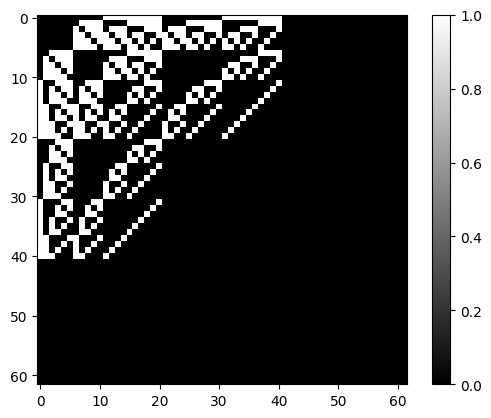

In [7]:
plt.imshow(A1_R, cmap='gray')
plt.colorbar()
plt.show()

In [8]:
GC_6 = nx.from_numpy_array(A1)

In [9]:
G6_R = nx.from_numpy_array(A1_R)

In [10]:
#Lista de enlaces válida
edges_v = list(GC_6.edges())

#Diccioario de aristas:
edges_v = {n: set(GC_6.neighbors(n)) for n in GC_6.nodes()}

for nodo in range(21, 41):
    print(nodo, edges_v.get(nodo, set()))

21 {3, 4, 5, 40, 18, 19, 20}
22 {2, 4, 5, 39, 16, 17, 20}
23 {2, 3, 5, 38, 15, 17, 19}
24 {2, 3, 4, 37, 15, 16, 18}
25 {1, 4, 5, 36, 13, 14, 20}
26 {1, 3, 35, 5, 12, 14, 19}
27 {1, 34, 3, 4, 12, 13, 18}
28 {1, 2, 33, 5, 11, 14, 17}
29 {32, 1, 2, 4, 11, 13, 16}
30 {1, 2, 3, 11, 12, 15, 31}
31 {0, 4, 5, 9, 10, 20, 30}
32 {0, 3, 5, 8, 10, 19, 29}
33 {0, 3, 4, 8, 9, 18, 28}
34 {0, 2, 5, 7, 10, 17, 27}
35 {0, 2, 4, 7, 9, 16, 26}
36 {0, 2, 3, 7, 8, 15, 25}
37 {0, 1, 5, 6, 10, 14, 24}
38 {0, 1, 4, 6, 9, 13, 23}
39 {0, 1, 3, 6, 8, 12, 22}
40 {0, 1, 2, 6, 7, 11, 21}


In [11]:
#Diccioario de aristas Regular:
edges_R = {n: set(G6_R.neighbors(n)) for n in G6_R.nodes()}
for nodo in range(21, 41):
    print(nodo, edges_R.get(nodo, set()))

21 {3, 4, 5, 18, 19, 20}
22 {2, 4, 5, 16, 17, 20}
23 {2, 3, 5, 15, 17, 19}
24 {2, 3, 4, 15, 16, 18}
25 {1, 4, 5, 13, 14, 20}
26 {1, 3, 5, 12, 14, 19}
27 {1, 3, 4, 12, 13, 18}
28 {1, 2, 5, 11, 14, 17}
29 {1, 2, 4, 11, 13, 16}
30 {1, 2, 3, 11, 12, 15}
31 {0, 4, 5, 9, 10, 20}
32 {0, 3, 5, 8, 10, 19}
33 {0, 3, 4, 8, 9, 18}
34 {0, 2, 5, 7, 10, 17}
35 {0, 2, 4, 7, 9, 16}
36 {0, 2, 3, 7, 8, 15}
37 {0, 1, 5, 6, 10, 14}
38 {0, 1, 4, 6, 9, 13}
39 {0, 1, 3, 6, 8, 12}
40 {0, 1, 2, 6, 7, 11}


In [12]:
grados = A1.sum(axis=1)

# Mostrar los grados con etiquetas
print(grados)

[31 31 31 31 31 31 15 15 15 15 15 15 15 15 15 15 15 15 15 15 15  7  7  7
  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  3  3  3  3  3  3  3
  3  3  3  3  3  3  3  3  1  1  1  1  1  1]


In [13]:
grados_R = A1_R.sum(axis=1)

# Mostrar los grados con etiquetas
print(grados_R)

[20 20 20 20 20 20 14 14 14 14 14 14 14 14 14 14 14 14 14 14 14  6  6  6
  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0]


Total de enlaces en HQC y regular

In [14]:
print("Enlaces iniciales completo:", GC_6.number_of_edges())
print("Enlaces iniciales regular:", G6_R.number_of_edges())

Enlaces iniciales completo: 301
Enlaces iniciales regular: 225


In [15]:
# Lista de reacciones del regular:
print(list(G6_R.edges()))

[(0, 11), (0, 12), (0, 13), (0, 14), (0, 15), (0, 16), (0, 17), (0, 18), (0, 19), (0, 20), (0, 31), (0, 32), (0, 33), (0, 34), (0, 35), (0, 36), (0, 37), (0, 38), (0, 39), (0, 40), (1, 7), (1, 8), (1, 9), (1, 10), (1, 15), (1, 16), (1, 17), (1, 18), (1, 19), (1, 20), (1, 25), (1, 26), (1, 27), (1, 28), (1, 29), (1, 30), (1, 37), (1, 38), (1, 39), (1, 40), (2, 6), (2, 8), (2, 9), (2, 10), (2, 12), (2, 13), (2, 14), (2, 18), (2, 19), (2, 20), (2, 22), (2, 23), (2, 24), (2, 28), (2, 29), (2, 30), (2, 34), (2, 35), (2, 36), (2, 40), (3, 6), (3, 7), (3, 9), (3, 10), (3, 11), (3, 13), (3, 14), (3, 16), (3, 17), (3, 20), (3, 21), (3, 23), (3, 24), (3, 26), (3, 27), (3, 30), (3, 32), (3, 33), (3, 36), (3, 39), (4, 6), (4, 7), (4, 8), (4, 10), (4, 11), (4, 12), (4, 14), (4, 15), (4, 17), (4, 19), (4, 21), (4, 22), (4, 24), (4, 25), (4, 27), (4, 29), (4, 31), (4, 33), (4, 35), (4, 38), (5, 6), (5, 7), (5, 8), (5, 9), (5, 11), (5, 12), (5, 13), (5, 15), (5, 16), (5, 18), (5, 21), (5, 22), (5, 23)

Algoritmo restringido de W-S

In [16]:
#Algoritmo propuesto

def constrained_rewire(G, edges_v, p):

    H = G.copy()
    edges = list(H.edges())

    for (u,v) in edges:

        if random.random() < p:

            vecinos = set(H.neighbors(u))
            candidatos = edges_v.get(u, set()) #Considerando todas los posibles enlaces del completo

            posibles = candidatos - vecinos - {u}

            if not posibles:
                continue

            w = random.choice(tuple(posibles))

            H.remove_edge(u,v)
            H.add_edge(u,w)

    return H

In [17]:
arreglo = np.logspace(-4,0,20)
corridas = 100

In [18]:
def constrained_rewire_debug(G, edges_v, p):

    H = G.copy()
    edges = list(H.edges())

    for i, (u, v) in enumerate(edges):

        print(f"\n--- Iteración {i+1} ---")
        print(f"Arista original: ({u}, {v})")

        if random.random() < p:

            vecinos = set(H.neighbors(u))
            candidatos = edges_v.get(u, set())
            posibles = candidatos - vecinos - {u}

            print("Vecinos de u:", vecinos)
            print("Candidatos:", candidatos)
            print("Posibles:", posibles)

            if not posibles:
                print("No hay posibles -> no cambia")
                continue

            w = random.choice(tuple(posibles))

            print(f"✅ Se elige: {w}")
            print(f"🔁 Rewire: ({u}, {v}) → ({u}, {w})")

            H.remove_edge(u, v)
            H.add_edge(u, w)

        else:
            print(" No ocurre rewiring")

    return H

Análisis de la reconexión: Muestra de cómo se van cambiando los enlaces en una iteración.

In [19]:
H = constrained_rewire_debug(G6_R, edges_v, p=1)


--- Iteración 1 ---
Arista original: (0, 11)
Vecinos de u: {11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40}
Candidatos: {1, 2, 3, 4, 5, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 51, 52, 53, 54, 55, 61}
Posibles: {1, 2, 3, 4, 5, 51, 52, 53, 54, 55, 61}
✅ Se elige: 61
🔁 Rewire: (0, 11) → (0, 61)

--- Iteración 2 ---
Arista original: (0, 12)
Vecinos de u: {12, 13, 14, 15, 16, 17, 18, 19, 20, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 61}
Candidatos: {1, 2, 3, 4, 5, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 51, 52, 53, 54, 55, 61}
Posibles: {1, 2, 3, 4, 5, 11, 51, 52, 53, 54, 55}
✅ Se elige: 3
🔁 Rewire: (0, 12) → (0, 3)

--- Iteración 3 ---
Arista original: (0, 13)
Vecinos de u: {3, 13, 14, 15, 16, 17, 18, 19, 20, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 61}
Candidatos: {1, 2, 3, 4, 5, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 51, 52, 53, 54, 55, 61

Se fija el parámetro $q=0.5$

In [20]:
#Propuesta de cambio de orden en los enlaces 50% cambiados

edges = list(G6_R.edges())

edges_random = [
    (u, v) if random.random() < 0.5 else (v, u)
    for (u, v) in edges]

In [21]:
print(edges)

[(0, 11), (0, 12), (0, 13), (0, 14), (0, 15), (0, 16), (0, 17), (0, 18), (0, 19), (0, 20), (0, 31), (0, 32), (0, 33), (0, 34), (0, 35), (0, 36), (0, 37), (0, 38), (0, 39), (0, 40), (1, 7), (1, 8), (1, 9), (1, 10), (1, 15), (1, 16), (1, 17), (1, 18), (1, 19), (1, 20), (1, 25), (1, 26), (1, 27), (1, 28), (1, 29), (1, 30), (1, 37), (1, 38), (1, 39), (1, 40), (2, 6), (2, 8), (2, 9), (2, 10), (2, 12), (2, 13), (2, 14), (2, 18), (2, 19), (2, 20), (2, 22), (2, 23), (2, 24), (2, 28), (2, 29), (2, 30), (2, 34), (2, 35), (2, 36), (2, 40), (3, 6), (3, 7), (3, 9), (3, 10), (3, 11), (3, 13), (3, 14), (3, 16), (3, 17), (3, 20), (3, 21), (3, 23), (3, 24), (3, 26), (3, 27), (3, 30), (3, 32), (3, 33), (3, 36), (3, 39), (4, 6), (4, 7), (4, 8), (4, 10), (4, 11), (4, 12), (4, 14), (4, 15), (4, 17), (4, 19), (4, 21), (4, 22), (4, 24), (4, 25), (4, 27), (4, 29), (4, 31), (4, 33), (4, 35), (4, 38), (5, 6), (5, 7), (5, 8), (5, 9), (5, 11), (5, 12), (5, 13), (5, 15), (5, 16), (5, 18), (5, 21), (5, 22), (5, 23)

Cambio aleatorio del orden de enlaces

In [22]:
print(edges_random)

[(11, 0), (12, 0), (13, 0), (0, 14), (15, 0), (16, 0), (0, 17), (0, 18), (0, 19), (0, 20), (31, 0), (32, 0), (33, 0), (34, 0), (0, 35), (36, 0), (0, 37), (0, 38), (0, 39), (0, 40), (7, 1), (1, 8), (9, 1), (1, 10), (15, 1), (1, 16), (17, 1), (18, 1), (1, 19), (1, 20), (1, 25), (1, 26), (27, 1), (28, 1), (29, 1), (30, 1), (1, 37), (1, 38), (39, 1), (40, 1), (6, 2), (2, 8), (9, 2), (2, 10), (2, 12), (2, 13), (14, 2), (2, 18), (19, 2), (2, 20), (22, 2), (2, 23), (24, 2), (28, 2), (29, 2), (30, 2), (2, 34), (2, 35), (36, 2), (40, 2), (3, 6), (3, 7), (9, 3), (10, 3), (11, 3), (3, 13), (3, 14), (3, 16), (3, 17), (20, 3), (21, 3), (23, 3), (24, 3), (26, 3), (3, 27), (3, 30), (32, 3), (33, 3), (36, 3), (39, 3), (4, 6), (4, 7), (4, 8), (10, 4), (4, 11), (4, 12), (4, 14), (15, 4), (17, 4), (19, 4), (4, 21), (22, 4), (4, 24), (4, 25), (4, 27), (29, 4), (31, 4), (4, 33), (4, 35), (4, 38), (5, 6), (7, 5), (8, 5), (5, 9), (11, 5), (12, 5), (13, 5), (5, 15), (5, 16), (18, 5), (21, 5), (5, 22), (5, 23)

In [23]:
#Prueba de que son los mismos enlaces
G1 = nx.Graph(edges)
G2 = nx.Graph(edges_random)

print(nx.is_isomorphic(G1, G2))

True


In [24]:
A_random = nx.adjacency_matrix(G2).todense()

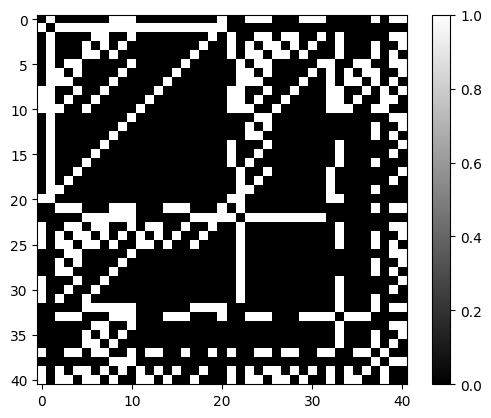

In [25]:
plt.imshow(A_random, cmap='gray')
plt.colorbar()
plt.show()

El cambio en el orden de enlaces modifica el orden de los hipernodos en la matriz de adyacencia lo que provoca una interpretación incorrecta en la evolución del bloque $M_{33}$ en la proyección 1.

In [26]:
nodos = sorted(G1.nodes())

A_Rp1 = nx.to_numpy_array(G1, nodelist=nodos)
A_Rp2 = nx.to_numpy_array(G2, nodelist=nodos)

In [27]:
# Lista de reacciones del regular:
print(list(G2.edges()))

[(11, 0), (11, 3), (11, 4), (11, 5), (11, 8), (11, 9), (11, 10), (11, 18), (11, 19), (11, 20), (11, 28), (11, 29), (11, 30), (11, 40), (0, 12), (0, 13), (0, 14), (0, 15), (0, 16), (0, 17), (0, 18), (0, 19), (0, 20), (0, 31), (0, 32), (0, 33), (0, 34), (0, 35), (0, 36), (0, 37), (0, 38), (0, 39), (0, 40), (12, 2), (12, 4), (12, 5), (12, 7), (12, 9), (12, 10), (12, 16), (12, 17), (12, 20), (12, 26), (12, 27), (12, 30), (12, 39), (13, 2), (13, 3), (13, 5), (13, 7), (13, 8), (13, 10), (13, 15), (13, 17), (13, 19), (13, 25), (13, 27), (13, 29), (13, 38), (14, 2), (14, 3), (14, 4), (14, 7), (14, 8), (14, 9), (14, 15), (14, 16), (14, 18), (14, 25), (14, 26), (14, 28), (14, 37), (15, 1), (15, 4), (15, 5), (15, 6), (15, 9), (15, 10), (15, 20), (15, 23), (15, 24), (15, 30), (15, 36), (16, 1), (16, 3), (16, 5), (16, 6), (16, 8), (16, 10), (16, 19), (16, 22), (16, 24), (16, 29), (16, 35), (17, 1), (17, 3), (17, 4), (17, 6), (17, 8), (17, 9), (17, 18), (17, 22), (17, 23), (17, 28), (17, 34), (18, 1

Se ordenan los nodos en orden de aparición

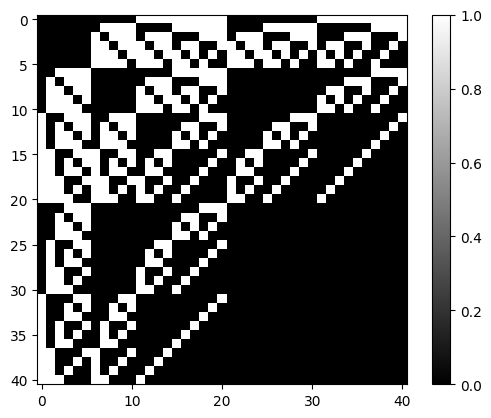

In [28]:
plt.imshow(A_Rp2, cmap='gray')
plt.colorbar()
plt.show()

Aquí se muestra que no hay evolución en el bloque M_33 cuando no se modifica el orden de los enlaces.

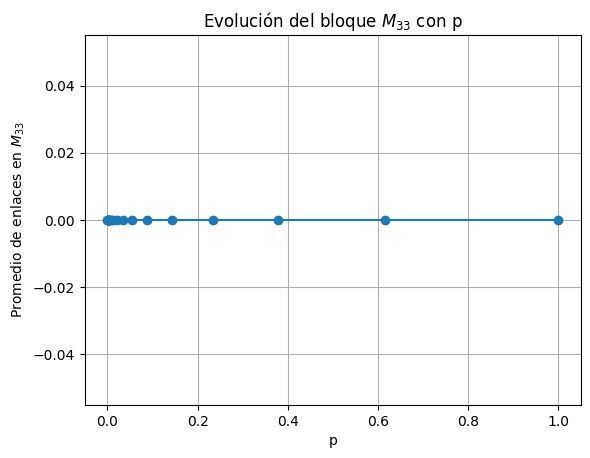

In [29]:
resultados = []

for p in arreglo:

    valores_corridas = []

    for _ in range(corridas):

        GWS = constrained_rewire(G6_R, edges_v, p)
        A = nx.to_numpy_array(GWS)

        # Bloque M33
        submat = A[21:41, 21:41]
        suma = np.sum(submat) / 2

        valores_corridas.append(suma)

    promedio = np.mean(valores_corridas)
    resultados.append(promedio)

# Gráfica
plt.figure()

plt.plot(arreglo, resultados, marker='o')


plt.xlabel("p")
plt.ylabel("Promedio de enlaces en $M_{33}$")
plt.title("Evolución del bloque $M_{33}$ con p")

plt.grid()
plt.show()

Prueba con cambio en el orden de los enlaces

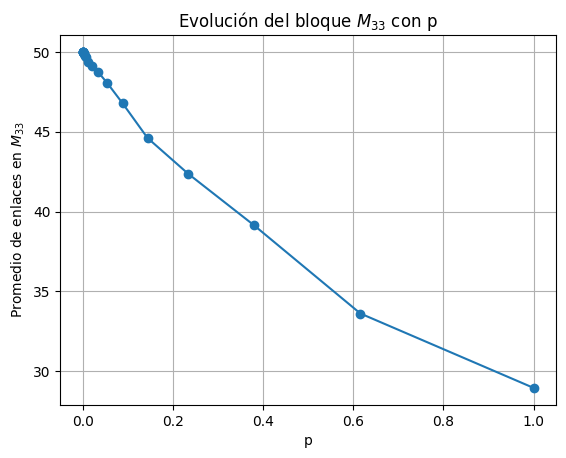

In [30]:
resultados = []

for p in arreglo:

    valores_corridas = []

    for _ in range(corridas):

        GWS = constrained_rewire(G2, edges_v, p)
        A = nx.to_numpy_array(GWS)

        # Bloque M33
        submat = A[21:41, 21:41]
        suma = np.sum(submat) / 2

        valores_corridas.append(suma)

    promedio = np.mean(valores_corridas)
    resultados.append(promedio)

# Gráfica
plt.figure()

plt.plot(arreglo, resultados, marker='o')


plt.xlabel("p")
plt.ylabel("Promedio de enlaces en $M_{33}$")
plt.title("Evolución del bloque $M_{33}$ con p")

plt.grid()
plt.show()

Este cambio no tiene sentido porque no hay tantos enlaces en el bloque M_33

Existen cambios en el bloque $M_33$ pero hay que fijar el orden de los nodos en P1 de la matriz de adyacencia.

In [31]:
H = constrained_rewire_debug(G2, edges_v, p=1)


--- Iteración 1 ---
Arista original: (11, 0)
Vecinos de u: {0, 3, 4, 5, 8, 9, 10, 40, 18, 19, 20, 28, 29, 30}
Candidatos: {0, 3, 4, 5, 8, 9, 10, 40, 18, 19, 20, 50, 28, 29, 30}
Posibles: {50}
✅ Se elige: 50
🔁 Rewire: (11, 0) → (11, 50)

--- Iteración 2 ---
Arista original: (11, 3)
Vecinos de u: {3, 4, 5, 8, 9, 10, 40, 18, 19, 20, 50, 28, 29, 30}
Candidatos: {0, 3, 4, 5, 8, 9, 10, 40, 18, 19, 20, 50, 28, 29, 30}
Posibles: {0}
✅ Se elige: 0
🔁 Rewire: (11, 3) → (11, 0)

--- Iteración 3 ---
Arista original: (11, 4)
Vecinos de u: {0, 4, 5, 8, 9, 10, 40, 18, 19, 20, 50, 28, 29, 30}
Candidatos: {0, 3, 4, 5, 8, 9, 10, 40, 18, 19, 20, 50, 28, 29, 30}
Posibles: {3}
✅ Se elige: 3
🔁 Rewire: (11, 4) → (11, 3)

--- Iteración 4 ---
Arista original: (11, 5)
Vecinos de u: {0, 3, 5, 8, 9, 10, 40, 18, 19, 20, 50, 28, 29, 30}
Candidatos: {0, 3, 4, 5, 8, 9, 10, 40, 18, 19, 20, 50, 28, 29, 30}
Posibles: {4}
✅ Se elige: 4
🔁 Rewire: (11, 5) → (11, 4)

--- Iteración 5 ---
Arista original: (11, 8)
Vecinos de u

In [33]:
# Crear copia
G_rand = G2.copy()

# Agregar 20 nodos nuevos (por ejemplo del 41 al 61)
G_rand.add_nodes_from(range(41, 62))

#Algoritmo correcto para la reconexión de W-S

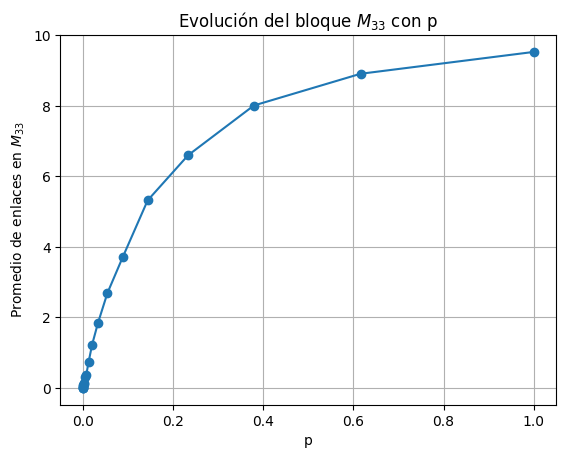

In [34]:
resultados = []

#  ORDEN FIJO DE NODOS
nodos = sorted(G6_R.nodes())

for p in arreglo:

    valores_corridas = []

    for _ in range(corridas):

        GWS = constrained_rewire(G_rand, edges_v, p)

        # usar nodelist fijo
        A = nx.to_numpy_array(GWS, nodelist=nodos)

        # Bloque M33
        submat = A[21:41, 21:41]
        suma = np.sum(submat) / 2

        valores_corridas.append(suma)

    promedio = np.mean(valores_corridas)
    resultados.append(promedio)

# Gráfica
plt.figure()
plt.plot(arreglo, resultados, marker='o')

plt.xlabel("p")
plt.ylabel("Promedio de enlaces en $M_{33}$")
plt.title("Evolución del bloque $M_{33}$ con p")

plt.grid()
plt.show()